<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 26795 stored elements and shape (5822, 219)>
  Coords	Values
  (0, 56)	0.3573351845928554
  (0, 67)	0.4188847015396265
  (0, 106)	0.4605788130081839
  (0, 129)	0.49189262450671206
  (0, 176)	0.49270272541555854
  (1, 64)	0.6064118798917887
  (1, 143)	0.60582439388392
  (1, 190)	0.51501595674434
  (2, 5)	0.6690236870321589
  (2, 61)	0.6696799598491521
  (2, 127)	0.3223911561540328
  (3, 49)	0.5418468875212257
  (3, 190)	0.45657167841205454
  (3, 198)	0.4543943794754184
  (3, 201)	0.5398796170042994
  (4, 72)	0.6531572541303814
  (4, 97)	0.6550442151303341
  (4, 105)	0.3798719226280679
  (5, 100)	0.5765575203742115
  (5, 147)	0.5781439649388758
  (5, 192)	0.5773482324426885
  (6, 79)	0.6685419654973047
  (6, 127)	0.3248629520700817
  (6, 132)	0.6689661446899331
  (7, 13)	0.4669094891328874
  :	:
  (5817, 72)	0.6531572541303814
  (5817, 97)	0.6550442151303341
  (5817, 105)	0.3798719226280679
  (5818, 16)	0.4656239680848506
  (5

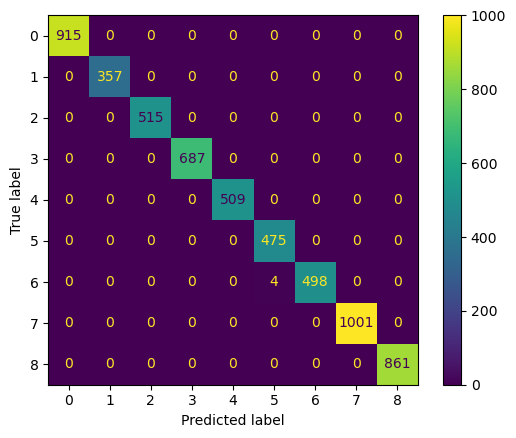

In [10]:
import pandas as pd
import pickle
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

try:
    with open("expense_model.pkl", 'rb') as e_file:
        expense_model= pickle.load(e_file)
    with open("X_test_vec.pkl", 'rb') as file:
        X_test_vec= pickle.load(file)
except FileNotFoundError:
    print(f"Error: The file was not found.") 

y_test= pd.read_csv("y_test.csv")
print(X_test_vec)
print(y_test)
print(expense_model)

from sklearn.preprocessing import LabelEncoder
le= LabelEncoder()
y_test_encoded= le.fit_transform(y_test.values.ravel())
y_predict=expense_model.predict(X_test_vec)
score= accuracy_score(y_test_encoded, y_predict)
print(score)
report=classification_report(y_test_encoded, y_predict)
print(report)
cm= confusion_matrix(y_test_encoded, y_predict )
print(cm)
disp= ConfusionMatrixDisplay(confusion_matrix= cm)
disp.plot()
plt.show()
disp.figure_.savefig("confusion_matrix.png")

with open('model_results.md', 'w') as f:
    f.write("# Model Performance Report\n\n")
    f.write(f"**Accuracy:** {score}\n\n")
    f.write("## Classification Report\n\n")
    f.write(report)



